# ANN para Recomendación de Acciones contra el Dengue

## 1. Importación de Librerías y Configuración del Entorno

In [18]:
# Importación de módulos del sistema y manipulación de datos
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn para preprocesamiento y evaluación de modelos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

# TensorFlow / Keras para arquitectura de Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical

# Configuración del estilo visual para gráficas
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid")

print("Librerías cargadas correctamente.")
print("Versión de TensorFlow:", tf.__version__)

Librerías cargadas correctamente.
Versión de TensorFlow: 2.22.0-rc0


## 2. Carga y Verificación del Dataset Procesado

In [19]:
# Búsqueda dinámica del archivo en carpetas habituales del proyecto
POSSIBLE_PATHS = [
    'dengue_procesado.csv',
    os.path.join('data', 'dengue_procesado.csv'),
    os.path.join('data', 'processed', 'dengue_procesado.csv'),
    os.path.join('..', 'dengue_procesado.csv'),
    os.path.join('..', 'data', 'processed', 'dengue_procesado.csv')
]

DATA_PATH = None

for path in POSSIBLE_PATHS:
    if os.path.exists(path):
        DATA_PATH = path
        break

if DATA_PATH:
    df = pd.read_csv(DATA_PATH)
    print(f"Dataset cargado exitosamente desde: {os.path.abspath(DATA_PATH)}")
    print(f"Dimensión del dataset: {df.shape}")
else:
    raise FileNotFoundError("No se encontró 'dengue_procesado.csv' en las rutas esperadas.")

# Visualización de los primeros 5 registros
df.head()

Dataset cargado exitosamente desde: C:\VectorIA\data\processed\dengue_procesado.csv
Dimensión del dataset: (566, 26)


,fecha_inicio_semana,anio,semana_epi,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,log_casos,mes,...,temp_max_c_lag6,temp_max_c_lag8,temp_min_c_lag2,temp_min_c_lag4,temp_min_c_lag6,temp_min_c_lag8,humedad_rel_pct_lag2,humedad_rel_pct_lag4,humedad_rel_pct_lag6,humedad_rel_pct_lag8
0,2014-02-23,2014,9,96,3.3,29.8,19.7,68.1,4.574711,2,...,27.1,27.2,20.0,18.7,19.5,19.9,77.4,78.0,81.7,84.9
1,2014-03-02,2014,10,75,4.6,29.9,20.3,68.0,4.330733,3,...,27.1,27.0,19.5,19.5,19.5,19.7,68.9,76.7,80.0,83.8
2,2014-03-09,2014,11,94,2.3,30.7,19.8,65.3,4.553877,3,...,27.2,27.1,19.7,20.0,18.7,19.5,68.1,77.4,78.0,81.7
3,2014-03-16,2014,12,71,4.7,31.2,20.7,65.7,4.276666,3,...,27.4,27.1,20.3,19.5,19.5,19.5,68.0,68.9,76.7,80.0
4,2014-03-23,2014,13,95,6.5,31.5,21.1,65.8,4.564348,3,...,28.8,27.2,19.8,19.7,20.0,18.7,65.3,68.1,77.4,78.0


## 3. Preprocesamiento: Construcción de la Variable Objetivo y Matriz de Características

In [20]:
# 1. Creación del nivel de riesgo epidemiológico en 3 clases a partir de los casos de dengue
# Clase 0: Riesgo Bajo | Clase 1: Riesgo Medio | Clase 2: Riesgo Alto
df['nivel_riesgo'] = pd.qcut(df['casos_dengue'], q=3, labels=[0, 1, 2])

# 2. Definición de la matriz de características X excluyendo la fecha y los contadores continuos de casos
DROP_COLS = ['fecha_inicio_semana', 'casos_dengue', 'log_casos', 'nivel_riesgo']
X = df.drop(columns=[col for col in DROP_COLS if col in df.columns])

# 3. Vector de etiquetas objetivo
y = df['nivel_riesgo'].astype(int).values

# 4. Conversión de variables categóricas (si existen) a One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# 5. Formato binario multiclase para Keras (Softmax)
y_encoded = to_categorical(y, num_classes=3)

print("Matriz de características (X):", X_encoded.shape)
print("Vector objetivo (y):", y_encoded.shape)
print("Distribución de clases (0: Bajo, 1: Medio, 2: Alto):")
print(pd.Series(y).value_counts().sort_index())

Matriz de características (X): (566, 23)
Vector objetivo (y): (566, 3)
Distribución de clases (0: Bajo, 1: Medio, 2: Alto):
0    192
1    185
2    189
Name: count, dtype: int64


## 4. División de Datos y Estandarización de Características

In [21]:
# División estratificada: 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Escalado numérico con StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Número de registros para entrenamiento: {X_train_scaled.shape[0]}")
print(f"Número de registros para prueba: {X_test_scaled.shape[0]}")

Número de registros para entrenamiento: 452
Número de registros para prueba: 114


## 5. Definición de la Arquitectura de la Red Neuronal (ANN)

In [22]:
input_dim = X_train_scaled.shape[1]

# Construcción del modelo denso secuencial
model = Sequential([
    Dense(128, activation='relu', input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(32, activation='relu'),
    BatchNormalization(),

    Dense(3, activation='softmax')
], name="ANN_Vector_IA")

# Compilación del modelo
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\VectorIA\.venv\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "ANN_Vector_IA"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,403 (56.26 KB)

 Trainable params: 13,955 (54.51 KB)

 Non-trainable params: 448 (1.75 KB)

## 6. Entrenamiento del Modelo

In [23]:
EPOCHS = 40
BATCH_SIZE = 32

history = model.fit(
    X_train_scaled,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.15,
    verbose=1
)

Epoch 1/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.3984 - loss: 1.5039 - val_accuracy: 0.5588 - val_loss: 0.9901
Epoch 2/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5234 - loss: 1.1025 - val_accuracy: 0.6471 - val_loss: 0.9110
Epoch 3/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6380 - loss: 0.8620 - val_accuracy: 0.6912 - val_loss: 0.8607
Epoch 4/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6198 - loss: 0.8203 - val_accuracy: 0.6912 - val_loss: 0.8249
Epoch 5/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6641 - loss: 0.8223 - val_accuracy: 0.7059 - val_loss: 0.8018
Epoch 6/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6745 - loss: 0.7031 - val_accuracy: 0.7353 - val_loss: 0.7780
Epoch 7/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7422 - loss: 0.6380 - val_accuracy: 0.7206 - val_loss: 0.7577
Epoch 8/40
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7005 - loss: 0.6637 - val_accuracy: 0.7059 - val_loss

## 7. Gráficas y Curvas de Aprendizaje (Loss y Accuracy)

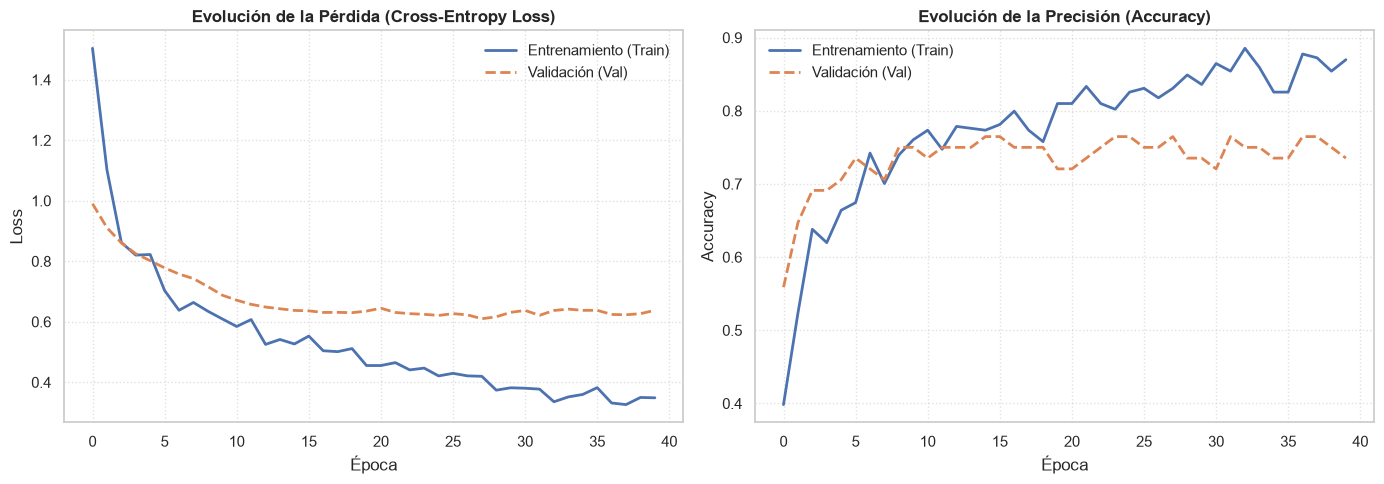

In [24]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de pérdida
ax1.plot(history.history['loss'], label='Entrenamiento (Train)', linewidth=2)
ax1.plot(history.history['val_loss'], label='Validación (Val)', linewidth=2, linestyle='--')
ax1.set_title('Evolución de la Pérdida (Cross-Entropy Loss)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle=':', alpha=0.6)

# Gráfico de precisión
ax2.plot(history.history['accuracy'], label='Entrenamiento (Train)', linewidth=2)
ax2.plot(history.history['val_accuracy'], label='Validación (Val)', linewidth=2, linestyle='--')
ax2.set_title('Evolución de la Precisión (Accuracy)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Época')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## 8. Evaluación en Test y Matriz de Confusión

Pérdida en conjunto de prueba: 0.7610
Precisión en conjunto de prueba: 68.42%

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
=== REPORTE DE CLASIFICACIÓN DETALLADO ===
              precision    recall  f1-score   support

 Riesgo Bajo       0.69      0.79      0.74        39
Riesgo Medio       0.57      0.54      0.56        37
 Riesgo Alto       0.79      0.71      0.75        38

    accuracy                           0.68       114
   macro avg       0.68      0.68      0.68       114
weighted avg       0.69      0.68      0.68       114



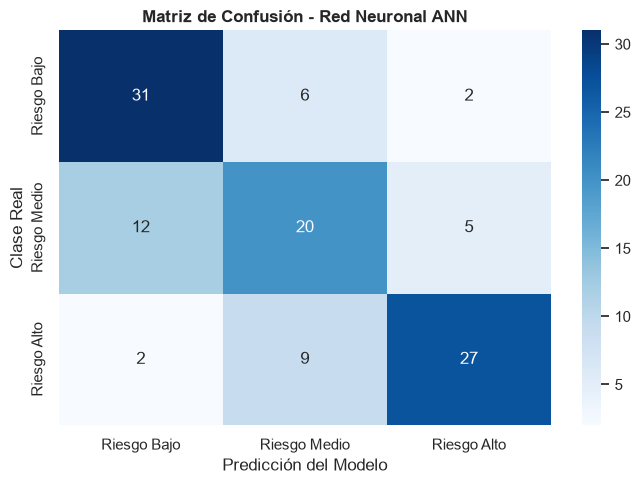

In [25]:
# Evaluación en el conjunto de prueba
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Pérdida en conjunto de prueba: {test_loss:.4f}")
print(f"Precisión en conjunto de prueba: {test_acc * 100:.2f}%\n")

# Predicciones
y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1)

# Reporte formal de métricas
target_names = ['Riesgo Bajo', 'Riesgo Medio', 'Riesgo Alto']
print("=== REPORTE DE CLASIFICACIÓN DETALLADO ===")
print(classification_report(y_true, y_pred, target_names=target_names))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names)
plt.title('Matriz de Confusión - Red Neuronal ANN', fontsize=12, fontweight='bold')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Clase Real')
plt.tight_layout()
plt.show()

## 9. Exportación de Artefactos para PyCharm

In [28]:
# 1. Detectar el directorio de trabajo actual
current_dir = os.getcwd()

# 2. Si el notebook está dentro de una subcarpeta (ej. 'notebooks'), sube un nivel a la raíz
if os.path.basename(current_dir) in ['notebooks', 'cuadernos', 'src']:
    PROJECT_ROOT = os.path.abspath(os.path.join(current_dir, '..'))
else:
    PROJECT_ROOT = current_dir

# 3. Ruta exacta hacia la carpeta 'models' de la raíz
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

print("Guardando archivos directamente en:", MODELS_DIR)

# 4. Guardar modelo Keras entrenado
model_path = os.path.join(MODELS_DIR, 'ann_control.h5')
model.save(model_path)
print(f"✓ Modelo guardado en: {model_path}")

# 5. Guardar objeto de escalado
scaler_path = os.path.join(MODELS_DIR, 'scaler_ann.pkl')
joblib.dump(scaler, scaler_path)
print(f"✓ Escalador guardado en: {scaler_path}")

# 6. Guardar lista de características esperadas por el modelo
columns_path = os.path.join(MODELS_DIR, 'ann_columns.pkl')
joblib.dump(X_encoded.columns.tolist(), columns_path)
print(f"✓ Estructura de características guardada en: {columns_path}")

print("\n¡Listo! Revisa la carpeta en el Explorador de archivos de Windows.")

Guardando archivos directamente en: C:\VectorIA\models
✓ Modelo guardado en: C:\VectorIA\models\ann_control.h5
✓ Escalador guardado en: C:\VectorIA\models\scaler_ann.pkl
✓ Estructura de características guardada en: C:\VectorIA\models\ann_columns.pkl

¡Listo! Revisa la carpeta en el Explorador de archivos de Windows.
